# Multimodal J-Lens: complete offline workflow

This notebook constructs a tiny **random-weight native Janus model**, creates four calibration images and one held-out image, encodes their visual tokens, calibrates the visual head and all four MJ transports, reloads the artifacts, computes a controlled modality index, and plots the live results.

It needs no downloads, cached probe results, or upstream lens package. Run every cell in order after installing this checkout with `pip install -e ".[transformers,visualization]"` (Transformers 5.3.x). Files go to `outputs/mj_lens`, or the `VLM_PROBING_OUTPUT` environment variable.

**Scope:** the model and vocabulary IDs are synthetic. This is an API and numerical-calibration demonstration, not a semantic interpretation or a reproduction of the paper's pretrained-model findings. `fit_batches` estimates Jacobians with a frozen backbone; it does not train an SAE or update model weights.


In [1]:
%matplotlib inline

## 1. Imports and output directory

All imports are shown. The later visualizations use the library plotters; no cells read prepared images or analysis results.

In [2]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F
from transformers import (JanusConfig, JanusForConditionalGeneration,
                          JanusVisionConfig, JanusVQVAEConfig, LlamaConfig)

from vlmprobe import Prober
from vlmprobe.adapters import prepare_janus_generation
from vlmprobe.api.mj import MJBatch, fit_visual_readout
from vlmprobe.lenses.mj_readout import LinearizedVisualReadout, modality_index
from vlmprobe.visualization import (plot_lens_heatmap, plot_mj_codebook,
                                   plot_mj_modality_index)

OUT = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/mj_lens"))
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
torch.manual_seed(71)


## 2. Construct the entire native model locally; no pretrained weights

MJ layer indices refer to **decoder block inputs**, so layer 0 is the merged embedding input. The target is the actual input to the final RMSNorm. This convention differs from the ordinary post-block residual lens indices.

In [3]:
config = JanusConfig(
    text_config=LlamaConfig(
        vocab_size=64, hidden_size=16, intermediate_size=32,
        num_hidden_layers=2, num_attention_heads=2, num_key_value_heads=2,
        max_position_embeddings=64, attn_implementation="eager",
    ),
    vision_config=JanusVisionConfig(
        hidden_size=16, num_hidden_layers=1, num_attention_heads=2,
        image_size=16, patch_size=8, projection_dim=16, num_image_tokens=4,
    ),
    vq_config=JanusVQVAEConfig(
        embed_dim=8, num_embeddings=32, latent_channels=32,
        base_channels=32, channel_multiplier=[1], num_res_blocks=1,
        projection_dim=16, image_token_embed_dim=16, num_patches=2,
    ),
    image_token_id=63,
)
config._name_or_path = "local/tiny-janus-mj-tutorial"
model = JanusForConditionalGeneration(config).eval().requires_grad_(False)
probe = Prober(model)
layers = [0, 1]  # MJ indices are BLOCK INPUTS; layer 0 is merged embeddings.
print("Native model:", type(model).__name__)
print("MJ block-input sites:", probe.spec.mj.sources)
print("Final target:", probe.spec.mj.final, "(before final RMSNorm)")


Native model: JanusForConditionalGeneration
MJ block-input sites: {0: 'embeddings', 1: 'residual.0'}
Final target: residual.1 (before final RMSNorm)


## 3. Make disjoint synthetic images and encode their native visual codes

Split complete images before any calibration. The understanding encoder consumes 16×16 images; this tiny, one-stage VQ consumes an explicitly pooled 2×2 image. A pretrained Janus checkpoint needs its own official preprocessing rather than these fixture settings.

In [4]:
def synthetic_image(seed):
    generator = torch.Generator().manual_seed(seed)
    image = torch.rand(1, 3, 16, 16, generator=generator) * 0.12
    color = torch.rand(1, 3, 1, 1, generator=generator) * 0.5 + 0.35
    y, x = seed % 8, (3 * seed) % 8
    image[:, :, y:y + 8, x:x + 8] += color
    return image.clamp(0, 1)


train_images = [synthetic_image(seed) for seed in (11, 19, 29, 37)]
test_image = synthetic_image(53)
train_ids = ["synthetic-seed-11", "synthetic-seed-19",
             "synthetic-seed-29", "synthetic-seed-37"]
test_id = "synthetic-seed-53"
assert test_id not in train_ids


def encode_visual_codes(image):
    # This tiny VQ has one resolution stage and no spatial downsampling.
    # Pool explicitly to its 2x2 grid; map [0,1] RGB to [-1,1]. The separate
    # understanding encoder below consumes the full 16x16 synthetic image.
    vq_pixels = F.adaptive_avg_pool2d(image, (2, 2)) * 2 - 1
    with torch.no_grad():
        codes = model.model.vqmodel.encode(vq_pixels, return_dict=True).image_tokens
    return codes.reshape(image.shape[0], 4).long()


train_codes = [encode_visual_codes(image) for image in train_images]
test_codes = encode_visual_codes(test_image)
print("Held-out native VQ codes:", test_codes.tolist())


Held-out native VQ codes: [[27, 14, 12, 0]]


## 4. Build understanding and image-output batches with explicit channel masks

The text-output context carries projected image features and synthetic text IDs. The image-output context uses the native VQ generation embeddings. The helper deliberately leaves `layout.token_ids=None` because visual code IDs and text IDs belong to separate alphabets. Code i predicts code i+1; the final code has no observed successor.

In [5]:
def text_output_batch(image, index):
    # IDs identify a synthetic text vocabulary; no tokenizer or linguistic
    # meaning is assigned to these random embedding rows. Four image slots
    # receive the real understanding encoder's projected patch features.
    ids = torch.tensor([[1, 63, 63, 63, 63, 5 + index, 20 + index, 7 + index]])
    inputs = {"input_ids": ids, "attention_mask": torch.ones_like(ids),
              "pixel_values": image * 2 - 1, "use_cache": False}
    targets = torch.zeros_like(ids, dtype=torch.bool)
    targets[:, 5:7] = True  # These text states each predict another supplied text ID.
    return MJBatch(inputs=inputs, target_masks={"text": targets}, context="text_output")


def image_output_batch(codes, index):
    prompt = {"input_ids": torch.tensor([[1, 35 + index, 45 + index]])}
    # This helper concatenates text and native generation-code embeddings.
    # Code i predicts code i+1; the last code has no observed successor.
    # The final text prompt position is not counted as a visual-position target.
    return prepare_janus_generation(probe, prompt, codes)


text_train = [text_output_batch(image, index) for index, image in enumerate(train_images)]
image_train = [image_output_batch(codes, index) for index, codes in enumerate(train_codes)]
text_test = text_output_batch(test_image, 4)
image_test = image_output_batch(test_codes, 4)
assert image_test.inputs.layout.token_ids is None  # Text IDs and VQ IDs are different alphabets.


## 5. Declare immutable identities and calibrate ONE shared visual head

The same calibrated visual readout is shared by both visual-target operators. It averages the GELU derivative at individual final-layer visual states and forms the bias-free effective head. Corpus identity and the native parameter hash are saved explicitly.

In [6]:
digest = hashlib.sha256()
for name, value in sorted(model.state_dict().items()):
    digest.update(name.encode())
    digest.update(value.detach().cpu().contiguous().numpy().tobytes())
model_hash = digest.hexdigest()
calibration_id = "synthetic-image-seeds-11-19-29-37;native-vq-pool2;prompt-v1"
binding = {
    "model_id": probe.adapter.model_id,
    "model_revision": "sha256:" + model_hash,
    "tokenizer_id": "synthetic-text-ids-64-v1",
    "calibration_id": calibration_id,
    "codebook_id": "native-tiny-janus-vq32-sha256:" + model_hash,
}
readout_binding = {
    "model_id": binding["model_id"], "readout_id": "Janus-generation-head",
    "calibration_id": calibration_id, "model_revision": binding["model_revision"],
}
visual_readout = fit_visual_readout(probe, image_train, binding=readout_binding)
visual_readout.save(OUT / "visual_readout.pt")
print("Visual head calibration positions:", visual_readout.n_samples)
print("W_eff shape:", tuple(visual_readout.weight.shape))


Visual head calibration positions: 12
W_eff shape: (32, 16)


## 6. Fit all FOUR transports with frozen backbone weights, then probe held-out inputs

Fit T→T and V→T in the understanding/text-output context, then T→V and V→V in the image-output context. Each fit prints its admissible causal-pair counts and odd/even split-half cosine. Stability on this tiny corpus does not establish semantic validity.

In [7]:
methods, results = {}, {}
for source, target in (("text", "text"), ("visual", "text"),
                       ("text", "visual"), ("visual", "visual")):
    key = source + "_to_" + target
    context = "text_output" if target == "text" else "image_output"
    method = probe.lens.mj(
        layers=layers, source=source, target=target, context=context,
        visual_readout=visual_readout if target == "visual" else None, binding=binding,
    )
    method.fit_batches(text_train if target == "text" else image_train, dim_batch=8)
    artifact_dir = OUT / key
    method.save(artifact_dir)
    methods[key] = method
    result = method.run(text_test if target == "text" else image_test)
    result.save(artifact_dir / "heldout_result")
    results[key] = result
    print(key, "logits:", tuple(result.tensors["logits"].shape),
          "causal pair counts:", method.calibration_report["pair_counts"],
          "split-half cosines:", method.calibration_report["split_half_cosine"])
    (artifact_dir / "calibration.json").write_text(
        json.dumps(method.calibration_report, indent=2) + "\n", encoding="utf-8")


text_to_text logits: (2, 4, 64) causal pair counts: [5, 5, 5, 5] split-half cosines: {'0': 0.9992437470603767, '1': 0.9995492842878713}
visual_to_text logits: (2, 4, 64) causal pair counts: [8, 8, 8, 8] split-half cosines: {'0': 0.9989502117790672, '1': 0.999383574607537}
text_to_visual logits: (2, 3, 32) causal pair counts: [9, 9, 9, 9] split-half cosines: {'0': 0.9482587961318435, '1': 0.9846337297366996}


visual_to_visual logits: (2, 4, 32) causal pair counts: [6, 6, 6, 6] split-half cosines: {'0': 0.9335216414526152, '1': 0.9736159184771528}


## 7. Reload the same calibrated visual head and every transport; verify exact readouts

Artifacts store calibrated operators and head statistics, not copies of the backbone. Loading requires matching immutable model, tokenizer/codebook and calibration bindings. Each replay is compared with the original logits.

In [8]:
head = probe.spec.mj.visual_head
loaded_readout = LinearizedVisualReadout(
    probe.spec.mj.norm, head.proj_out, head.activation_fn, head.vision_head,
    binding=readout_binding,
).load(OUT / "visual_readout.pt")
for key, original in methods.items():
    restored = probe.lens.mj(
        layers=layers, source=original.source, target=original.target,
        context=original.context, binding=binding,
        visual_readout=loaded_readout if original.target == "visual" else None,
    ).load(OUT / key)
    replayed = restored.run(text_test if original.target == "text" else image_test)
    torch.testing.assert_close(replayed.tensors["logits"], results[key].tensors["logits"], rtol=0, atol=0)
print("All four save/load readouts match exactly. No optimizer or SAE training was used.")


All four save/load readouts match exactly. No optimizer or SAE training was used.


## 8. Compare shared-head linearization with native and affine controls on held-out states

The native nonlinear head and the affine control make visual-head approximation error inspectable on held-out states. These are random-model numerical controls, not task accuracy.

In [9]:
trace = probe._run(image_test.inputs, capture=[probe.spec.mj.final])
raw_final = trace.activations[probe.spec.mj.final]
selected_visual = image_test.target_masks["visual"]
native_logits = visual_readout.native(raw_final)[selected_visual]
linear_logits = visual_readout(raw_final)[selected_visual]
affine_logits = visual_readout.affine(raw_final)[selected_visual]
fidelity = {
    "linear_vs_native_mse": (linear_logits - native_logits).square().mean().item(),
    "affine_vs_native_mse": (affine_logits - native_logits).square().mean().item(),
    "note": "Random-model mechanical checks; neither result establishes semantic fidelity.",
}
print("Held-out head controls:", fidelity)


Held-out head controls: {'linear_vs_native_mse': 7.43711652262391e-08, 'affine_vs_native_mse': 7.999049245199785e-08, 'note': 'Random-model mechanical checks; neither result establishes semantic fidelity.'}


## 9. Controlled modality index in MATCHING visual-source coordinates

Both dictionaries use the same **visual-source coordinates at block input 1**. Their text-output and image-output calibration contexts remain explicit. Raw MI is dictionary allocation; the rotated-control and excess MI must be inspected alongside it. Size-matched text subsampling is also computed. This tiny example does not replace the paper’s sampling-noise controls or semantic evaluations.

In [10]:
mi_layer = 1
source_site = probe.spec.mj.sources[mi_layer]
trace = probe._run(image_test.inputs, capture=[source_site])
source_mask = image_test.inputs.layout.visual
activations = trace.activations[source_site][source_mask]
# Both dictionaries map into the SAME layer and visual-source hidden space.
# Their calibration output contexts differ and remain explicit in metadata.
text_dictionary = methods["visual_to_text"].dictionary(mi_layer)
visual_dictionary = methods["visual_to_visual"].dictionary(mi_layer)
mi = modality_index(activations, text_dictionary, visual_dictionary,
                    k=4, seed=73, size_match=True)
mi.metadata.update({"layer": mi_layer, "source_modality": "visual",
                    "text_dictionary_context": "text_output",
                    "visual_dictionary_context": "image_output",
                    "model_status": "random weights; no semantic interpretation"})
mi.save(OUT / "modality_index")
print("Raw MI:", mi.tensors["raw_mi"].tolist())
print("Rotated-dictionary control:", mi.tensors["rotated_mi"].tolist())
print("Excess MI:", mi.tensors["excess_mi"].tolist())
print("Size-matched excess MI:", mi.tensors["size_matched_excess_mi"].tolist())


Raw MI: [0.5806329846382141, 0.5773018002510071, 0.5740315914154053, 0.5730781555175781]
Rotated-dictionary control: [0.7002900242805481, 0.6964312195777893, 0.6927856206893921, 0.6929520964622498]
Excess MI: [-0.11965703964233398, -0.11912941932678223, -0.11875402927398682, -0.11987394094467163]
Size-matched excess MI: [0.11924135684967041, 0.12284630537033081, 0.12377578020095825, 0.11787575483322144]


## 10. Plot the live readouts through the library visualization tools

The V→V visualization decodes several visual source positions; it does not turn one text state into an image. The display wrapper explicitly converts native VQ pixel units to [0,1]. These images are position-wise readouts and can echo teacher-forced codes; they are not fresh autoregressive generations.

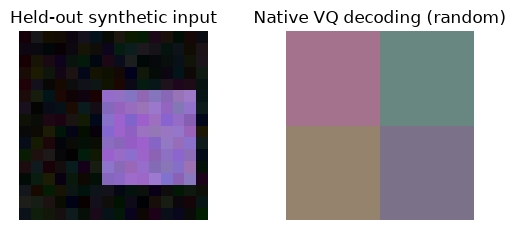

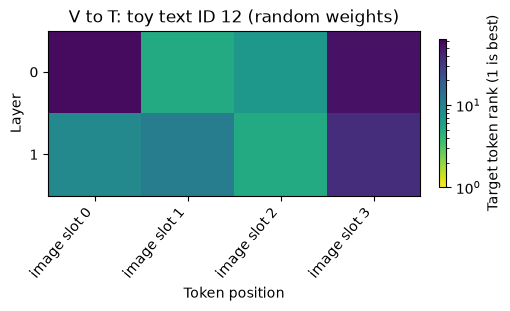

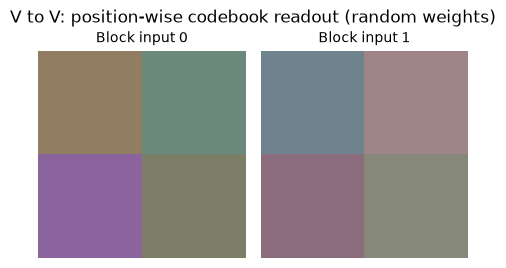

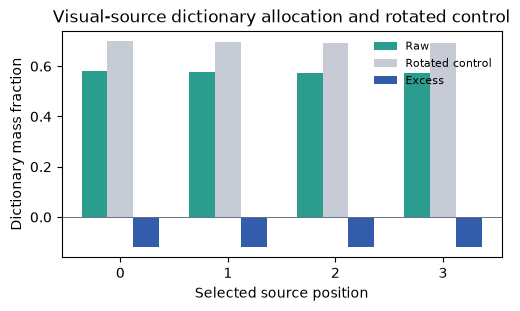

In [11]:
def decode_display(codes):
    # Native Janus returns HWC float VQ pixels, in the [-1,1] units used above.
    # Convert explicitly for display; the numerical codebook result is intact.
    return (probe.spec.mj.decode_visual_codes(codes).float().clamp(-1, 1) + 1) / 2


fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.4))
axes[0].imshow(test_image[0].permute(1, 2, 0).numpy())
axes[0].set_title("Held-out synthetic input")
native_vq = decode_display(test_codes)
axes[1].imshow(native_vq[0].numpy())
axes[1].set_title("Native VQ decoding (random)")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "input_and_native_vq.png", dpi=160, bbox_inches="tight")
plt.show()

visual_text = results["visual_to_text"]
ax = plot_lens_heatmap(
    visual_text, target_token_id=12, value_kind="rank",
    token_labels=["image slot " + str(i) for i in range(4)],
    title="V to T: toy text ID 12 (random weights)",
)
ax.figure.savefig(OUT / "visual_to_text.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plot_mj_codebook(
    results["visual_to_visual"], grid=(2, 2), decoder=decode_display,
)
fig.suptitle("V to V: position-wise codebook readout (random weights)")
fig.savefig(OUT / "visual_codebook.png", dpi=160, bbox_inches="tight")
plt.show()

ax = plot_mj_modality_index(mi)
ax.set_title("Visual-source dictionary allocation and rotated control")
ax.figure.savefig(OUT / "modality_index.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close("all")


## 11. Save the complete experimental provenance

The provenance file records train/test image identities, exact parameter hash, tap convention, native VQ codes, calibration reports and held-out head controls. Repeat runs overwrite this tutorial’s own output artifacts.

In [12]:
summary = {
    "model_status": "tiny random Janus; offline mechanical API demonstration",
    "training": "backbone frozen; only Jacobian and head-slope calibration; no optimizer",
    "model_binding": binding, "train_image_ids": train_ids, "test_image_id": test_id,
    "layers": layers, "tap_convention": "decoder_block_input",
    "visual_grid": [2, 2], "train_native_codes": [codes.tolist() for codes in train_codes],
    "test_native_codes": test_codes.tolist(), "fidelity": fidelity,
    "calibration": {key: method.calibration_report for key, method in methods.items()},
}
(OUT / "experiment.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("Outputs:", OUT.resolve())


Outputs: /data/gexinh/project/gexin/vlmprobe_mj_lens/outputs/mj_lens
